## Kathmandu AQI Classification: Decision Tree Classifier

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
import joblib
from sklearn.metrics import f1_score

df = pd.read_csv("kathmandu_final.csv", parse_dates=["time"]).sort_values("time")


df["hour"] = df["time"].dt.hour
df["month"] = df["time"].dt.month

df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24.0)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24.0)
df["month_sin"] = np.sin(2 * np.pi * (df["month"] - 1) / 12.0)
df["month_cos"] = np.cos(2 * np.pi * (df["month"] - 1) / 12.0)

labels = ["Healthy", "OK", "Unhealthy", "Dangerous"]
df["aqi_class"] = pd.cut(df["us_aqi"], bins=[-np.inf, 50, 100, 200, np.inf], labels=labels)

### Time-based split
Time series data, so no shuffling: first 3 years for training, last year for testing. The partial 2022 months (Aug-Sep) are dropped so both sets are whole years.

In [5]:
df = df[df["time"] >= "2022-10-01"]

train = df[df["time"] < "2025-10-01"]
test  = df[df["time"] >= "2025-10-01"]


kept_features = [
    "temperature_2m",
    "dew_point_2m",
    "cloud_cover",
    "precipitation",
    "hour_sin",
    "hour_cos",
    "month_sin",
    "month_cos"
]

X_train, y_train = train[kept_features], train["aqi_class"]
X_test,  y_test  = test[kept_features],  test["aqi_class"]

print(f"Train: {train['time'].min().date()} to {train['time'].max().date()} ({len(train)} rows)")
print(f"Test:  {test['time'].min().date()} to {test['time'].max().date()} ({len(test)} rows)")
print("\nClass counts (train):\n", y_train.value_counts().reindex(labels).to_string())

Train: 2022-10-01 to 2025-09-30 (26304 rows)
Test:  2025-10-01 to 2026-09-30 (8760 rows)

Class counts (train):
 aqi_class
Healthy        597
OK           14240
Unhealthy    11457
Dangerous       10


### Feature selection
A Decision Tree ranks the features; we keep only those with above-average importance.

In [6]:

selected_features = kept_features
print("Selected features:", selected_features)

Selected features: ['temperature_2m', 'dew_point_2m', 'cloud_cover', 'precipitation', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos']


### Train and evaluate

In [7]:
param_grid = {
    "max_depth": [3, 4, 6, 8, 10],
    "min_samples_leaf": [5, 10, 20, 50],
    "criterion": ["gini", "entropy"],
}

search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=TimeSeriesSplit(n_splits=5),
    scoring="accuracy",
)
search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print(f"Best CV accuracy: {search.best_score_:.4f}\n")


model = search.best_estimator_
pred = model.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, pred):.4f}\n")
print(classification_report(y_test, pred, labels=labels, zero_division=0))
print(f"Test macro F1: {f1_score(y_test, pred, average='macro'):.4f}")


joblib.dump({"model": model, "features": selected_features}, "best_aqi_model.joblib")
print("Saved best model to best_aqi_model.joblib")
#4

Best parameters: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 50}
Best CV accuracy: 0.6970

Test accuracy: 0.8365

              precision    recall  f1-score   support

     Healthy       0.00      0.00      0.00        20
          OK       0.80      0.85      0.83      3912
   Unhealthy       0.87      0.83      0.85      4793
   Dangerous       0.00      0.00      0.00        35

    accuracy                           0.84      8760
   macro avg       0.42      0.42      0.42      8760
weighted avg       0.83      0.84      0.84      8760

Test macro F1: 0.4196
Saved best model to best_aqi_model.joblib


### Plots

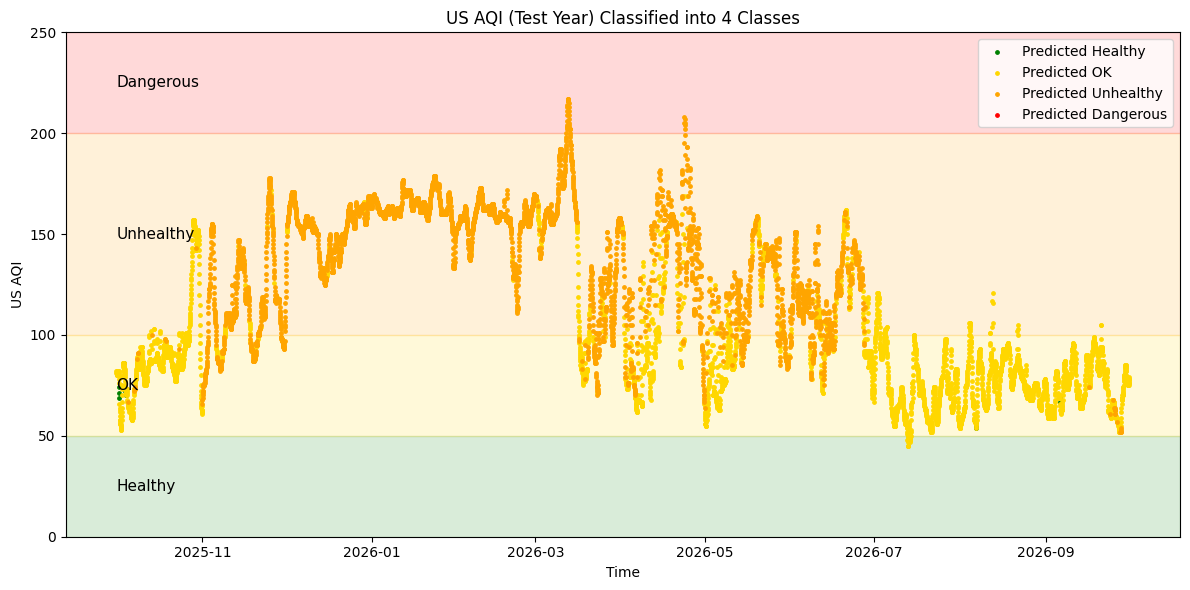

In [8]:
colors = {"Healthy": "green", "OK": "gold", "Unhealthy": "orange", "Dangerous": "red"}
bands = [(0, 50, "Healthy"), (50, 100, "OK"), (100, 200, "Unhealthy"), (200, 250, "Dangerous")]

plt.figure(figsize=(12, 6))


for low, high, name in bands:
    plt.axhspan(low, high, color=colors[name], alpha=0.15)
    plt.text(test["time"].iloc[0], (low + high) / 2, name, fontsize=11, va="center")


for name in labels:
    mask = pred == name
    plt.scatter(test["time"][mask], test["us_aqi"][mask], s=6, color=colors[name], label=f"Predicted {name}")

plt.title("US AQI (Test Year) Classified into 4 Classes")
plt.xlabel("Time")
plt.ylabel("US AQI")
plt.ylim(0, 250)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()
#5

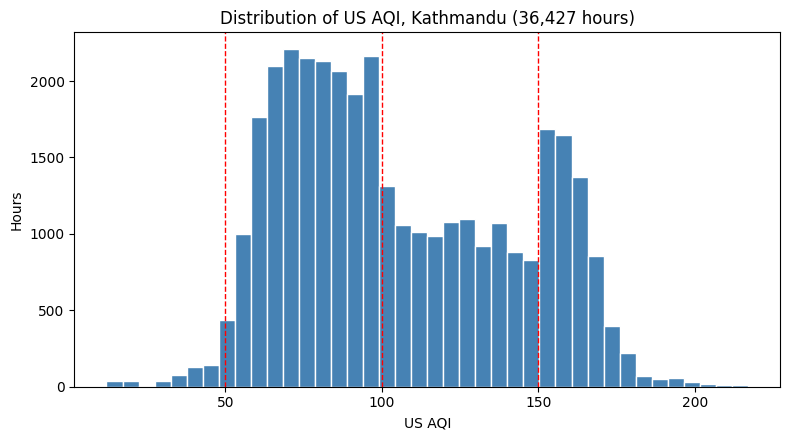

In [9]:

plt.figure(figsize=(8, 4.5))
plt.hist(df["us_aqi"], bins=40, color="steelblue", edgecolor="white")


for v in [50, 100, 150]:
    plt.axvline(v, color="red", linestyle="--", linewidth=1)

plt.title("Distribution of US AQI, Kathmandu (36,427 hours)")
plt.xlabel("US AQI")
plt.ylabel("Hours")
plt.tight_layout()
plt.savefig("fig1_aqi_histogram.png", dpi=150)
plt.show()
#6

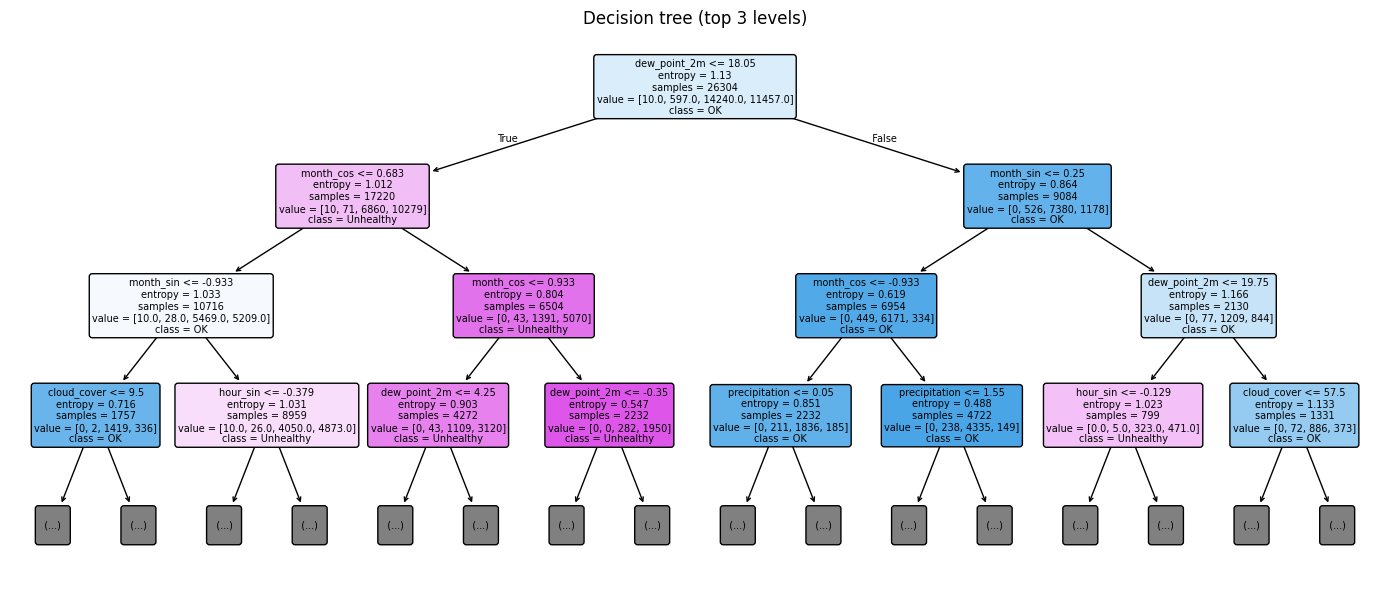

In [10]:
from sklearn.tree import plot_tree
plt.figure(figsize=(14, 6))
plot_tree(model, max_depth=3, feature_names=selected_features,
          class_names=list(model.classes_), filled=True, rounded=True, fontsize=7)
plt.title("Decision tree (top 3 levels)")
plt.tight_layout()
plt.savefig("fig2_tree.png", dpi=130)
plt.show()
#7


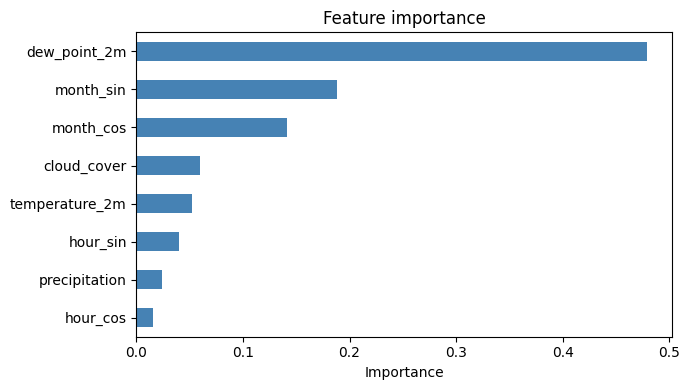

In [11]:

imp = pd.Series(model.feature_importances_, index=selected_features).sort_values()
plt.figure(figsize=(7, 4))
imp.plot(kind="barh", color="steelblue")
plt.title("Feature importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("fig3_feature_importance.png", dpi=150)
plt.show()
#8